# Avaliação dos modelos de previsão do subitem do IPCA

**Pergunta:** o modelo consegue prever a variação de preço do mês seguinte melhor do que regras simples? Se não conseguir, não adianta usá-lo para recomendar reajuste ao lojista.

O que se prevê é a **variação mensal do subitem do IPCA** (em %) no mês t+1, para os 45 subitens dos produtos do atacadista. Na fase de aplicação, essa variação vira R$ com o preço do atacadista (`atacado.preco_atual`, ADR 0004); aqui nenhum preço é lido.

| Modelo | Como prevê t+1 |
|---|---|
| Ingênua | repete a variação de t |
| Ingênua sazonal | repete a variação do mesmo mês do ano anterior |
| Regressão linear | reta `índice = a + b·t` nos últimos 24 meses |
| Regressão logarítmica | curva `índice = a + b·ln(t)` nos últimos 24 meses |
| XGBoost sem clima | defasagens, médias móveis, mês do ano, subitem, dólar e Selic |
| XGBoost com clima | o anterior + El Niño/La Niña e clima dos polos agrícolas |

Cada regressão aparece em duas leituras: **pelo nível** (a reta em t+1 contra o índice real de t) e **pela tendência** (a reta em t+1 contra a própria reta em t, isto é, a taxa de crescimento da tendência).

**Validação walk-forward:** para cada um dos últimos 36 meses, todos os modelos são refeitos só com o que já se sabia naquele mês e preveem o seguinte. Nada de divisão aleatória. Praça: **Brasil**. A lógica está em `src/inflatrack/predicao/` (com testes); este notebook só carrega, roda e mostra.

Para refazer: `just modelo-notebook`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from inflatrack.atacado.importar_tabela import ler_csv
from inflatrack.predicao.serie import carregar_gold, subitens_do_atacado
from inflatrack.predicao.walk_forward import avaliar, metricas, origens_de_teste

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRACA = 1  # Brasil
MESES_TESTE = 36
JANELA_REGRESSAO = 24

NOMES_MODELO = {
    "ingenua": "Ingênua",
    "ingenua_sazonal": "Ingênua sazonal",
    "linear": "Linear (nível)",
    "logaritmica": "Logarítmica (nível)",
    "linear_tendencia": "Linear (tendência)",
    "logaritmica_tendencia": "Logarítmica (tendência)",
    "xgboost_sem_clima": "XGBoost sem clima",
    "xgboost_com_clima": "XGBoost com clima",
}
NOMES_GRUPO = {"11": "Alimentação", "21": "Limpeza", "63": "Higiene"}
tabela = ler_csv((RAIZ / "data/atacado/tabela_exemplo.csv").read_text(encoding="utf-8"))
NOME_SUBITEM = {linha.codigo_subitem_ipca: linha.produto for linha in tabela}
pd.set_option("display.precision", 3)

## Dados

A base tem uma linha por subitem e mês t, com as variáveis conhecidas em t e o alvo (a variação de t+1).

In [2]:
codigos = subitens_do_atacado()
base = carregar_gold(RAIZ / "data/duckdb/inflatrack.duckdb", codigos, PRACA)
inicio, fim = base.mes.min(), base.mes.max()
print(f"{len(codigos)} subitens, {len(base)} linhas, de {inicio:%m/%Y} a {fim:%m/%Y}")

45 subitens, 10818 linhas, de 07/2006 a 10/2026


In [3]:
origens = origens_de_teste(base, MESES_TESTE)
previsoes = avaliar(base, origens, janela=JANELA_REGRESSAO)
previsoes["modelo_nome"] = previsoes["modelo"].map(NOMES_MODELO)
primeiro, ultimo = (o + pd.DateOffset(months=1) for o in (origens[0], origens[-1]))
print(f"Meses previstos: {primeiro:%m/%Y} a {ultimo:%m/%Y}")

Meses previstos: 11/2023 a 10/2026


## Resultado geral

MAE e RMSE em **pontos percentuais** da variação mensal. `ganho_sobre_ingenua` = `1 − MAE do modelo / MAE da ingênua`: positivo quer dizer que o modelo erra menos que repetir o mês anterior. Todos os modelos são comparados nas mesmas linhas.

In [4]:
geral = metricas(previsoes).assign(modelo=lambda d: d.modelo.map(NOMES_MODELO))
geral.sort_values("mae").set_index("modelo")

,mae,rmse,n,ganho_sobre_ingenua
modelo,,,,
XGBoost sem clima,1.734,3.898,1620,0.215
XGBoost com clima,1.757,3.922,1620,0.205
Logarítmica (tendência),2.109,4.644,1620,0.046
Ingênua,2.209,5.037,1620,0.000
Linear (tendência),2.258,4.842,1620,-0.022
Ingênua sazonal,2.619,5.304,1620,-0.185
Linear (nível),6.036,10.900,1620,-1.732
Logarítmica (nível),6.261,10.958,1620,-1.834


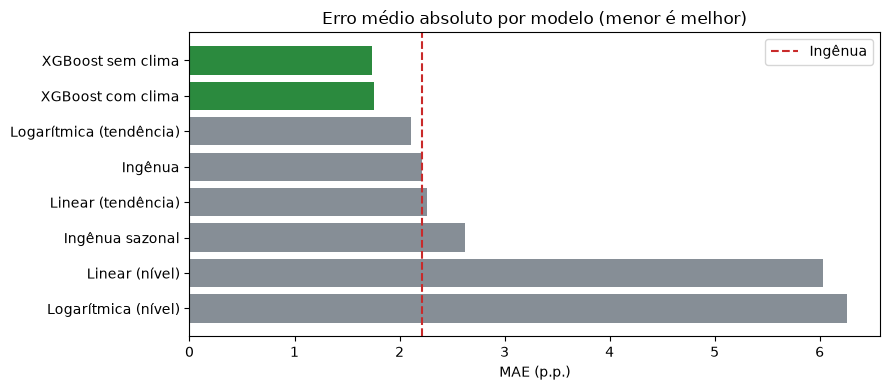

In [5]:
ordem = geral.sort_values("mae")
fig, eixo = plt.subplots(figsize=(9, 4))
cores = ["#2b8a3e" if "XGBoost" in m else "#868e96" for m in ordem.modelo]
eixo.barh(ordem.modelo, ordem.mae, color=cores)
mae_ingenua = geral.set_index("modelo").loc["Ingênua", "mae"]
eixo.axvline(mae_ingenua, color="#c92a2a", ls="--", label="Ingênua")
eixo.invert_yaxis()
eixo.set_xlabel("MAE (p.p.)")
eixo.set_title("Erro médio absoluto por modelo (menor é melhor)")
eixo.legend()
plt.tight_layout()

## Por grupo do IPCA

In [6]:
por_grupo = metricas(previsoes, por=["grupo"])
por_grupo["grupo"] = por_grupo.grupo.map(NOMES_GRUPO)
por_grupo["modelo"] = por_grupo.modelo.map(NOMES_MODELO)
por_grupo.pivot(index="modelo", columns="grupo", values="mae").loc[ordem.modelo]

grupo,Alimentação,Higiene,Limpeza
modelo,,,
XGBoost sem clima,2.027,0.518,0.600
XGBoost com clima,2.056,0.517,0.594
Logarítmica (tendência),2.488,0.547,0.629
Ingênua,2.586,0.670,0.731
Linear (tendência),2.668,0.565,0.660
Ingênua sazonal,3.072,0.712,0.882
Linear (nível),6.990,1.972,2.417
Logarítmica (nível),7.227,2.146,2.600


## Por subitem: onde o XGBoost ganha e onde perde

Ganho do XGBoost sem clima sobre a ingênua, por produto.

In [7]:
por_subitem = metricas(previsoes, por=["codigo_subitem"])
xgb = por_subitem[por_subitem.modelo == "xgboost_sem_clima"].copy()
xgb["produto"] = xgb.codigo_subitem.map(NOME_SUBITEM)
colunas = ["produto", "codigo_subitem", "mae", "ganho_sobre_ingenua"]
xgb = xgb.sort_values("ganho_sobre_ingenua")[colunas].set_index("produto")
pd.concat({"Piores 5": xgb.head(5), "Melhores 5": xgb.tail(5)})

codigo_subitem    mae  ganho_sobre_ingenua
           produto                                                         
Piores 5   Arroz Tipo 1                 1101002  1.403               -0.152
           Café Torrado e Moído         1114022  1.241               -0.085
           Feijão Carioca Tipo 1        1101073  3.440               -0.032
           Açúcar Refinado              1104003  0.900               -0.018
           Açúcar Cristal               1104004  0.722               -0.018
Melhores 5 Macarrão Instantâneo         1102061  1.016                0.297
           Fubá de Milho                1102008  1.120                0.298
           Batata-inglesa               1103003  9.640                0.305
           Tomate                       1103028  9.972                0.327
           Pão de Forma                 1112018  0.974                0.346

## Previsto contra real em quatro produtos

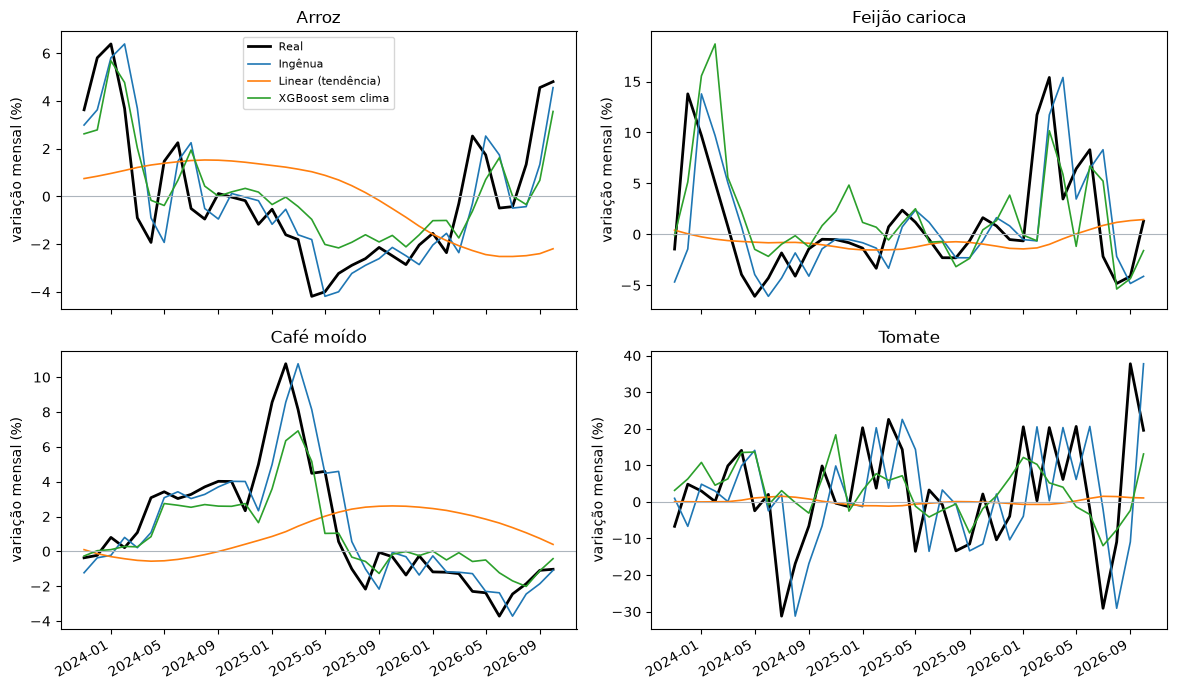

In [8]:
exemplos = {
    "1101002": "Arroz",
    "1101073": "Feijão carioca",
    "1114022": "Café moído",
    "1103028": "Tomate",
}
mostrar = ["ingenua", "linear_tendencia", "xgboost_sem_clima"]
fig, eixos = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for eixo, (codigo, nome) in zip(eixos.flat, exemplos.items(), strict=True):
    dados = previsoes[previsoes.codigo_subitem == codigo]
    real = dados[dados.modelo == "ingenua"].set_index("mes_alvo").real
    eixo.plot(real.index, real.values, color="black", lw=2, label="Real")
    for modelo in mostrar:
        serie = dados[dados.modelo == modelo].set_index("mes_alvo").previsto
        eixo.plot(serie.index, serie.values, lw=1.2, label=NOMES_MODELO[modelo])
    eixo.axhline(0, color="#adb5bd", lw=0.8)
    eixo.set_title(nome)
    eixo.set_ylabel("variação mensal (%)")
eixos.flat[0].legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()

## O clima ajuda? (Regra 8 da Seção 2.4)

In [9]:
comparacao = por_grupo[por_grupo.modelo.isin(["XGBoost sem clima", "XGBoost com clima"])]
comparacao.pivot(index="grupo", columns="modelo", values="mae")

modelo,XGBoost com clima,XGBoost sem clima
grupo,,
Alimentação,2.056,2.027
Higiene,0.517,0.518
Limpeza,0.594,0.600


## Conclusão

Números da execução de 19/11/2026, com 36 meses previstos (nov/2023 a out/2026), 45 subitens e praça Brasil.

1. **O XGBoost é o melhor modelo.** Ele erra em média **1,73 p.p.**, contra 2,21 p.p. da ingênua (repetir o mês anterior), um ganho de **cerca de 21%**. O ganho aparece nos três grupos: alimentação (2,03 contra 2,59), higiene (0,52 contra 0,67) e limpeza (0,60 contra 0,73).
2. **As regressões que a professora sugeriu servem de régua, mas não de modelo.**
   - Pela tendência, a logarítmica (2,11) e a linear (2,26) empatam com a ingênua.
   - Pelo nível, as duas erram cerca de 6 p.p. A reta "puxa" o índice de volta para ela, e um mês fora da curva vira previsão de queda ou alta forte.
   - Uma tendência de 24 meses só diz o ritmo médio, não o que acontece no mês seguinte.
3. **O clima, do jeito que entrou, não ajudou.**
   - Com clima, o XGBoost ficou praticamente igual ao sem clima (1,76 contra 1,73). Pela Regra 8, o bloco de clima não entra no modelo da fase de aplicação.
   - O índice dos polos cobre poucos dados: só 16 subitens o recebem, e o SPI-3 começa em 2016.
   - Vale testar de novo com as defasagens longas da Regra 4 (3 a 9 meses para grãos), que não entraram nesta versão.
4. **Onde o XGBoost perde para a ingênua: arroz, café e feijão.** São justamente os grãos, cujo preço segue ciclos longos de safra e câmbio. Para esses itens, a fase de aplicação pode usar a ingênua, ou um modelo próprio do grupo, até haver variáveis melhores.
5. **Os hortifrútis são os mais difíceis.** Tomate e batata erram cerca de 10 p.p. por mês, mesmo com o XGBoost tendo ali o maior ganho (cerca de 30%). Para esses itens, a recomendação ao lojista deve vir com uma faixa, e não com um número só.

**Próximo passo (fase de aplicação):** usar o XGBoost sem clima, retreinado a cada mês novo do IPCA e rodado em todas as praças disponíveis. A variação prevista vira R$ com `atacado.preco_atual` e é gravada em `public.recomendacao_reajuste`.
